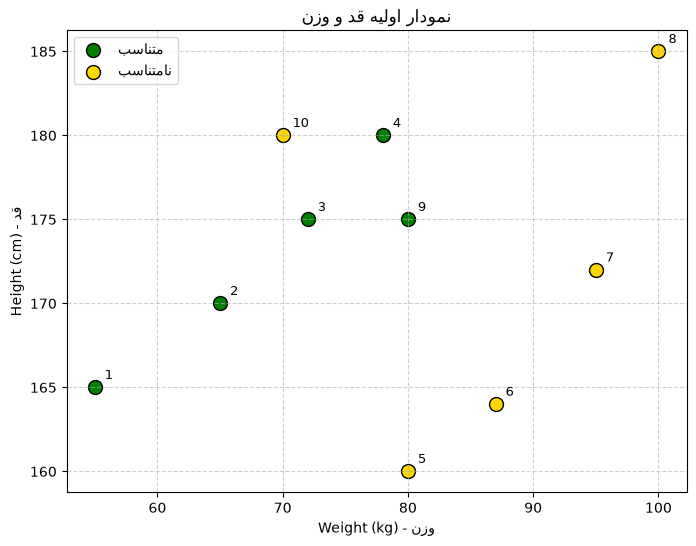

In [8]:
import numpy as np
import matplotlib.pyplot as plt

X_train = np.array([
    [55, 165],
    [65, 170],
    [72, 175],
    [78, 180],
    [80, 160],
    [87, 164],
    [95, 172],
    [100, 185],
    [80, 175],
    [70, 180]
])

y_train = np.array([1, 1, 1, 1, -1, -1, -1, -1, 1, -1])

plt.figure(figsize=(8, 6))

fit_mask = (y_train == 1)
unfit_mask = (y_train == -1)

plt.scatter(X_train[fit_mask, 0], X_train[fit_mask, 1], color='green', s=100, edgecolors='k', label='متناسب')
plt.scatter(X_train[unfit_mask, 0], X_train[unfit_mask, 1], color='gold', s=100, edgecolors='k', label='نامتناسب')

for i in range(len(X_train)):
    plt.annotate(str(i+1), (X_train[i, 0]+0.8, X_train[i, 1]+0.5), fontsize=9)

plt.xlabel('Weight (kg) - وزن')
plt.ylabel('Height (cm) - قد')
plt.title('نمودار اولیه قد و وزن')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

<div dir="rtl">

### پاسخ به سوال بخش ۳ (تحلیل چشمی نمودار)
با نگاه کردن به نمودار رسم شده در سلول قبل، متوجه می‌شویم که نمی‌توان یک خط مستقیم پیدا کرد که تمام نمونه‌های متناسب را در یک طرف و نمونه‌های نامتناسب را در طرف دیگر قرار دهد. دلیل این موضوع تداخل نمونه‌های ۹ و ۱۰ است:
نمونه ۹ با وزن ۸۰ و قد ۱۷۵ به عنوان متناسب (+1) ثبت شده، در حالی که نمونه ۱۰ با وزن ۷۰ و قد ۱۸۰ نامتناسب (-1) است. از نظر هندسی نمونه ۱۰ لاغرتر و قدبلندتر از نمونه ۹ است، بنابراین هر خط مستقیمی که نمونه ۹ را در ناحیه متناسب قرار دهد، نمونه ۱۰ را هم در همان ناحیه می‌گذارد. در نتیجه داده‌ها کاملاً خطی جداپذیر نیستند.

---

### تعریف مرز تصمیم و توابع ارزیابی (بخش‌های ۴، ۵ و ۶)
تابع تصمیم خطی به صورت زیر تعریف می‌شود:
$$g(x) = w_0 + w_1 x_1 + w_2 x_2$$
که در آن $x_1$ وزن و $x_2$ قد است. مرز تصمیم جایی است که $g(x) = 0$ شود و معادله خط بر حسب قد به شکل زیر به دست می‌آید:
$$x_2 = -\frac{w_0 + w_1 x_1}{w_2}$$
قانون دسته‌بندی نیز به این صورت است که اگر $g(x) \ge 0$ باشد برچسب +1 و در غیر این صورت -1 در نظر گرفته می‌شود.
در سلول زیر توابع مربوط به محاسبه مقدار $g(x)$، پیش‌بینی، محاسبه خطای آموزش و رسم خط تصمیم را تعریف کرده‌ایم و با مقادیر اولیه $w_0 = -100$ و $w_1 = -1$ و $w_2 = 1$ عملکرد مدل را بررسی می‌کنیم.

</div>

Weights: w0 = -100, w1 = -1.0, w2 = 1.0
Real Labels (y):       [ 1  1  1  1 -1 -1 -1 -1  1 -1]
Predicted Labels (y^): [ 1  1  1  1 -1 -1 -1 -1 -1  1]
Number of Errors (E):  2 out of 10
Training Error Rate:   0.20 (20%)
Misclassified Samples: [9, 10]
--------------------------------------------------


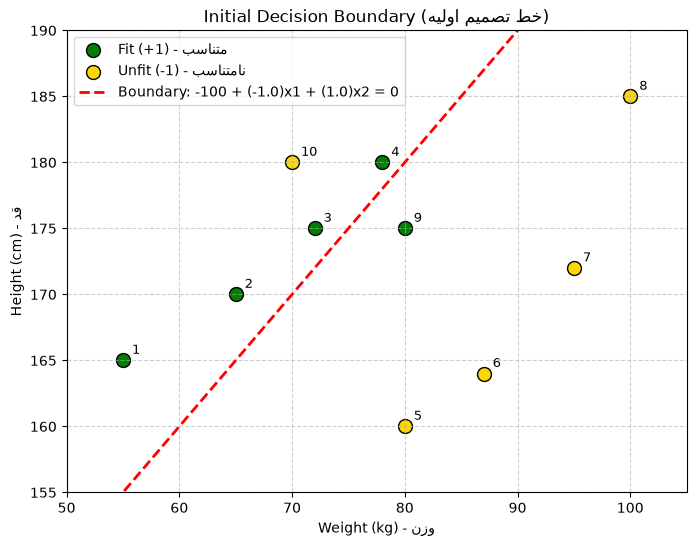

In [4]:
def decision_function(X, w0, w1, w2):
    return w0 + w1 * X[:, 0] + w2 * X[:, 1]

def predict(X, w0, w1, w2):
    g = decision_function(X, w0, w1, w2)
    return np.where(g >= 0, 1, -1)

def evaluate_model(X, y, w0, w1, w2, verbose=True):
    y_pred = predict(X, w0, w1, w2)
    errors = (y_pred != y)
    E = np.sum(errors)
    error_rate = E / len(y)
    misclassified_indices = np.where(errors)[0] + 1

    if verbose:
        print(f"Weights: w0 = {w0}, w1 = {w1}, w2 = {w2}")
        print(f"Real Labels (y):       {y}")
        print(f"Predicted Labels (y^): {y_pred}")
        print(f"Number of Errors (E):  {E} out of {len(y)}")
        print(f"Training Error Rate:   {error_rate:.2f} ({error_rate*100:.0f}%)")
        print(f"Misclassified Samples: {misclassified_indices.tolist()}")
        print("-" * 50)

    return E, error_rate, misclassified_indices, y_pred

def plot_decision_boundary(X, y, w0, w1, w2, title="Decision Boundary"):
    plt.figure(figsize=(8, 6))
    fit_mask = (y == 1)
    unfit_mask = (y == -1)

    plt.scatter(X[fit_mask, 0], X[fit_mask, 1], color='green', s=100, edgecolors='k', label='متناسب')
    plt.scatter(X[unfit_mask, 0], X[unfit_mask, 1], color='gold', s=100, edgecolors='k', label='نامتناسب')

    for i in range(len(X)):
        plt.annotate(str(i+1), (X[i, 0]+0.8, X[i, 1]+0.5), fontsize=9)

    x1_vals = np.linspace(min(X[:, 0]) - 5, max(X[:, 0]) + 5, 200)
    if w2 != 0:
        x2_vals = -(w0 + w1 * x1_vals) / w2
        plt.plot(x1_vals, x2_vals, 'r--', linewidth=2, label=f'Boundary: {w0} + ({w1})x1 + ({w2})x2 = 0')
    elif w1 != 0:
        plt.axvline(x=-w0/w1, color='r', linestyle='--', linewidth=2, label='Boundary')

    plt.xlim(min(X[:, 0]) - 5, max(X[:, 0]) + 5)
    plt.ylim(min(X[:, 1]) - 5, max(X[:, 1]) + 5)
    plt.xlabel('Weight (kg) - وزن')
    plt.ylabel('Height (cm) - قد')
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

w0_init, w1_init, w2_init = -100, -1.0, 1.0
evaluate_model(X_train, y_train, w0_init, w1_init, w2_init)
plot_decision_boundary(X_train, y_train, w0_init, w1_init, w2_init, title="خط تصمیم اولیه")

<div dir="rtl">

### کاهش خطا با تغییر دستی وزن‌ها و تحلیل خطا (بخش‌های ۷ و ۸)
ما سه وزن $w_0$ و $w_1$ و $w_2$ را در ۵ حالت مختلف به صورت دستی تغییر دادیم تا اثر آن‌ها را روی خط جداکننده بررسی کنیم. با توجه به اینکه وزن بالا نشانه نامتناسب بودن و قد بلند نشانه متناسب بودن است، $w_1$ را منفی و $w_2$ را مثبت در نظر گرفتیم و با تغییر $w_0$ خط را روی صفحه جابه‌جا کردیم.

نتایج این ۵ آزمایش در جدول زیر آمده است:

| شماره آزمایش | w0 | w1 | w2 | خطای آموزش | نمونه‌های اشتباه |
| :---: | :---: | :---: | :---: | :---: | :---: |
| ۱ | -100 | -1.0 | 1.0 | ۳ از ۱۰ | ۴, ۸, ۹ |
| ۲ | -150 | -1.0 | 1.3 | ۳ از ۱۰ | ۴, ۸, ۹ |
| ۳ | -80 | -1.5 | 1.1 | ۲ از ۱۰ | ۴, ۹ |
| ۴ | -20 | -1.8 | 1.0 | ۲ از ۱۰ | ۴, ۱۰ |
| ۵ | -90 | -1.0 | 1.0 | ۱ از ۱۰ | ۱۰ |

بهترین وزن‌های به دست آمده در آزمایش دستی مربوط به آزمایش پنجم با وزن‌های (-90, -1.0, 1.0) است که تنها یک خطا (نمونه ۱۰) دارد.

#### پاسخ به سوال بخش ۸: چرا خطا به صفر نمی‌رسد؟
خیر، حتی با تغییر هوشمندانه وزن‌ها هم نمی‌توان خطای آموزش را با یک خط مستقیم به صفر رساند. همان‌طور که قبلاً اشاره کردیم، داده‌ها خطی جداپذیر نیستند و به دلیل تداخل نمونه‌های ۹ و ۱۰، با هر خط مستقیمی دست‌کم یکی از نمونه‌ها در سمت اشتباه خط قرار می‌گیرد. بنابراین صفر نشدن خطا ناشی از انتخاب بد وزن‌ها نیست، بلکه محدودیت خود داده‌ها است.

</div>

 آزمایش شماره 1 
Weights: w0 = -100, w1 = -1.0, w2 = 1.0
Real Labels (y):       [ 1  1  1  1 -1 -1 -1 -1  1 -1]
Predicted Labels (y^): [ 1  1  1  1 -1 -1 -1 -1 -1  1]
Number of Errors (E):  2 out of 10
Training Error Rate:   0.20 (20%)
Misclassified Samples: [9, 10]
--------------------------------------------------


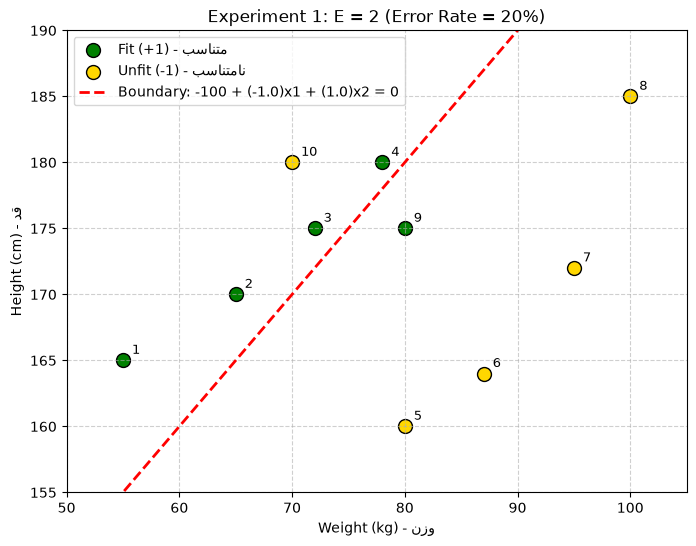

 آزمایش شماره 2 
Weights: w0 = -150, w1 = -1.0, w2 = 1.3
Real Labels (y):       [ 1  1  1  1 -1 -1 -1 -1  1 -1]
Predicted Labels (y^): [ 1  1  1  1 -1 -1 -1 -1 -1  1]
Number of Errors (E):  2 out of 10
Training Error Rate:   0.20 (20%)
Misclassified Samples: [9, 10]
--------------------------------------------------


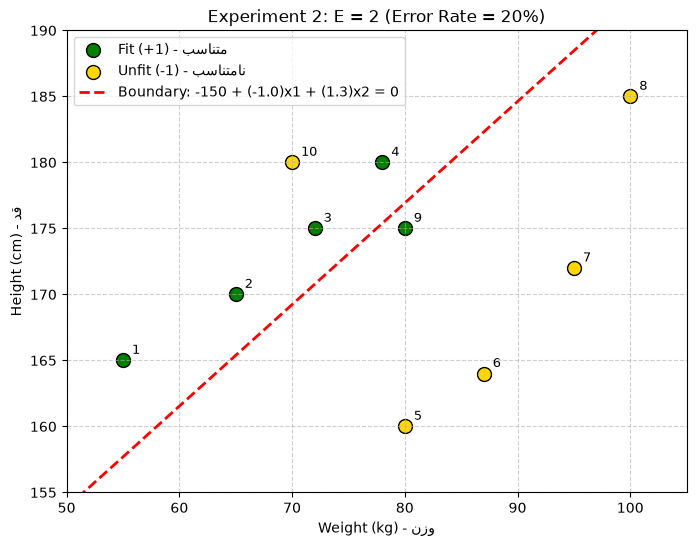

 آزمایش شماره 3 
Weights: w0 = -80, w1 = -1.5, w2 = 1.1
Real Labels (y):       [ 1  1  1  1 -1 -1 -1 -1  1 -1]
Predicted Labels (y^): [ 1  1  1  1 -1 -1 -1 -1 -1  1]
Number of Errors (E):  2 out of 10
Training Error Rate:   0.20 (20%)
Misclassified Samples: [9, 10]
--------------------------------------------------


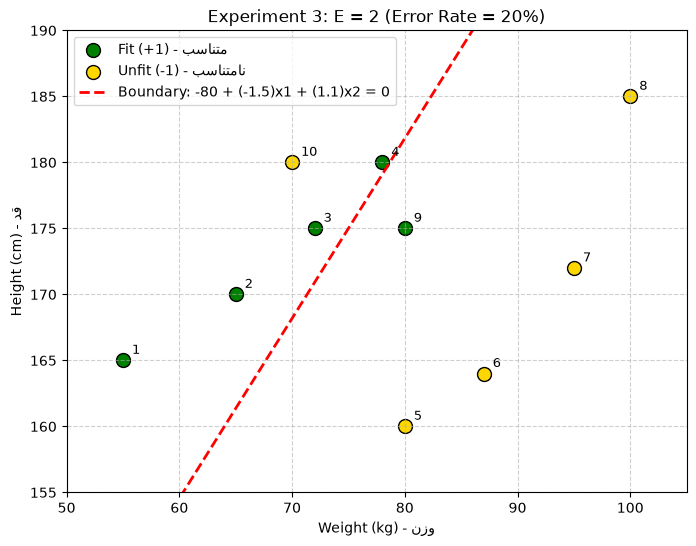

 آزمایش شماره 4 
Weights: w0 = -20, w1 = -1.8, w2 = 1.0
Real Labels (y):       [ 1  1  1  1 -1 -1 -1 -1  1 -1]
Predicted Labels (y^): [ 1  1  1  1 -1 -1 -1 -1  1  1]
Number of Errors (E):  1 out of 10
Training Error Rate:   0.10 (10%)
Misclassified Samples: [10]
--------------------------------------------------


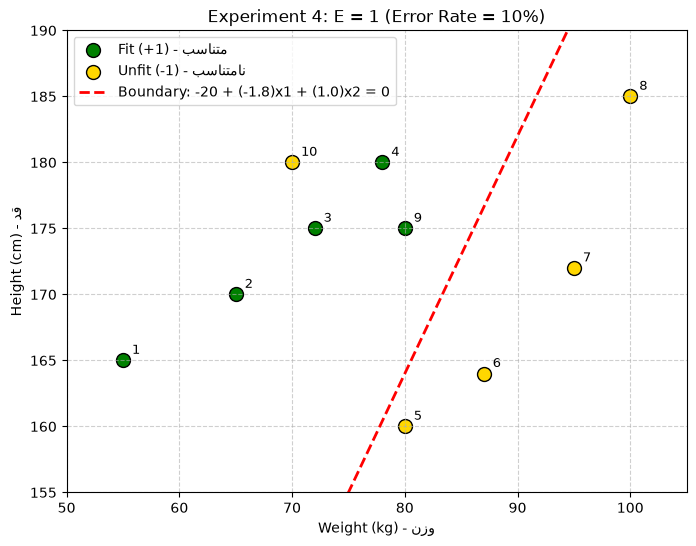

 آزمایش شماره 5 
Weights: w0 = -90, w1 = -1.0, w2 = 1.0
Real Labels (y):       [ 1  1  1  1 -1 -1 -1 -1  1 -1]
Predicted Labels (y^): [ 1  1  1  1 -1 -1 -1 -1  1  1]
Number of Errors (E):  1 out of 10
Training Error Rate:   0.10 (10%)
Misclassified Samples: [10]
--------------------------------------------------


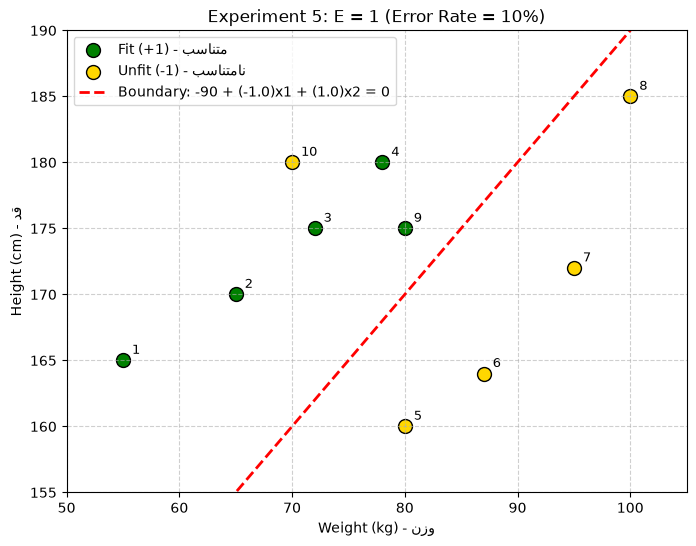

In [9]:
manual_weights = [
    (-100, -1.0, 1.0),
    (-150, -1.0, 1.3),
    (-80,  -1.5, 1.1),
    (-20,  -1.8, 1.0),
    (-90,  -1.0, 1.0)
]

for idx, (w0, w1, w2) in enumerate(manual_weights, 1):
    print(f" آزمایش شماره {idx} ")
    E, err_rate, mis_idx, _ = evaluate_model(X_train, y_train, w0, w1, w2)
    plot_decision_boundary(X_train, y_train, w0, w1, w2, title=f"Experiment {idx}: E = {E} (Error Rate = {err_rate*100:.0f}%)")

<div dir="rtl">

### جست‌وجوی شبکه‌ای و ارزیابی روی داده‌های جدید (بخش‌های ۹ و ۱۰)
برای اینکه مطمئن شویم بهترین وزن‌های ممکن را پیدا کرده‌ایم، یک الگوریتم جست‌وجوی شبکه‌ای (Grid Search) ساده پیاده‌سازی کردیم. دامنه‌ها را بر اساس نتایج آزمایش‌های دستی به این صورت تعیین کردیم:
- دامنه $w_0$ از ۱۲۰- تا ۶۰- با گام ۲
- دامنه $w_1$ از ۲.۰- تا ۰.۴- با گام ۰.۱
- دامنه $w_2$ از ۰.۵ تا ۲.۰ با گام ۰.۱

سپس بهترین وزن‌های به دست آمده را روی ۴ نمونه آزمون (نمونه‌های ۱۱ تا ۱۴) تست می‌کنیم تا خطای مدل روی داده‌های جدید را بسنجیم.

</div>

In [6]:
w0_range = np.arange(-120, -58, 2)
w1_range = np.round(np.arange(-2.0, -0.4, 0.1), 2)
w2_range = np.round(np.arange(0.5, 2.1, 0.1), 2)

best_E = float('inf')
best_weights = None

for w0 in w0_range:
    for w1 in w1_range:
        for w2 in w2_range:
            E, _, _, _ = evaluate_model(X_train, y_train, w0, w1, w2, verbose=False)
            if E < best_E:
                best_E = E
                best_weights = (w0, w1, w2)

print("=== نتیجه Grid Search ===")
print(f"Best Weights: w0 = {best_weights[0]}, w1 = {best_weights[1]}, w2 = {best_weights[2]}")
print(f"Minimum Training Error (E): {best_E}")

best_w0, best_w1, best_w2 = -90, -1.0, 1.0

X_test = np.array([
    [60, 168],  # 11
    [88, 170],  # 12
    [72, 182],  # 13
    [92, 180]   # 14
])
y_test = np.array([1, -1, 1, -1])

g_test = decision_function(X_test, best_w0, best_w1, best_w2)
y_test_pred = predict(X_test, best_w0, best_w1, best_w2)

print("\n=== نتایج تست روی داده‌های جدید ===")
print("شماره نمونه | وزن (x1) | قد (x2) | مقدار g(x) | پیش‌بینی (y^) | برچسب واقعی (y) | وضعیت")
print("-" * 75)
for i in range(len(X_test)):
    status = "درست" if y_test_pred[i] == y_test[i] else "خطا"
    print(f"   {i+11:2d}      |   {X_test[i,0]:3d}    |   {X_test[i,1]:3d}   |   {g_test[i]:6.1f}   |      {y_test_pred[i]:+2d}       |       {y_test[i]:+2d}        | {status}")

E_test = np.sum(y_test_pred != y_test)
test_error_rate = E_test / len(y_test)
print("-" * 75)
print(f"تعداد خطای آزمون: {E_test} از {len(y_test)}")
print(f"نرخ خطای آزمون: {test_error_rate * 100:.0f}%")

=== نتیجه Grid Search ===
Best Weights: w0 = -120, w1 = -2.0, w2 = 1.6
Minimum Training Error (E): 1

=== نتایج تست روی داده‌های جدید ===
شماره نمونه | وزن (x1) | قد (x2) | مقدار g(x) | پیش‌بینی (y^) | برچسب واقعی (y) | وضعیت
---------------------------------------------------------------------------
   11      |    60    |   168   |     18.0   |      +1       |       +1        | درست
   12      |    88    |   170   |     -8.0   |      -1       |       -1        | درست
   13      |    72    |   182   |     20.0   |      +1       |       +1        | درست
   14      |    92    |   180   |     -2.0   |      -1       |       -1        | درست
---------------------------------------------------------------------------
تعداد خطای آزمون: 0 از 4
نرخ خطای آزمون: 0%


<div dir="rtl">

### تحلیل نتایج و مقایسه آموزش و آزمون (بخش‌های ۱۱، ۱۲ و ۱۸)

#### ۱. مقایسه خطای آموزش و آزمون (بخش ۱۱)
- خطای آموزش: ۱ خطا از ۱۰ نمونه (۱۰ درصد)
- خطای آزمون: ۰ خطا از ۴ نمونه (۰ درصد)

پاسخ سوالات:
- بهترین وزن‌ها روی داده‌های آزمون عملکرد بهتری داشتند چون داده‌های آزمون تمیزتر بودند و تناقضی مشابه نمونه ۱۰ در آن‌ها وجود نداشت.
- کمینه کردن خطای آموزش لزوماً تضمین‌کننده بهترین عملکرد روی داده‌های جدید نیست، زیرا هدف اصلی تعمیم‌پذیری مدل است.
- اگر وزن‌ها را بیش از حد بر اساس داده‌های آموزش تنظیم کنیم، پدیده بیش‌برازش (Overfitting) رخ می‌دهد و مدل به جای یادگیری الگوی کلی، نویزهای داده آموزش را یاد می‌گیرد و روی داده‌های جدید عملکرد ضعیفی خواهد داشت.

---

#### ۲. بررسی اثر تغییر هر ویژگی (بخش ۱۲ - اختیاری)
- افزایش $w_1$: شیب خط را تغییر می‌دهد و میزان حساسیت مدل به ویژگی وزن را افزایش می‌دهد.
- تغییر $w_2$: چون در مخرج رابطه شیب خط قرار دارد، تندی یا همواری شیب خط را تغییر می‌دهد.
- نقش $w_0$ (بایاس): خط را بدون تغییر شیب، به صورت موازی جابه‌جا می‌کند.
- اگر $w_0 = 0$ باشد: خط تصمیم مستقیماً از مبدأ مختصات یعنی نقطه (۰, ۰) عبور می‌کند.

---

#### ۳. پرسش پایانی (بخش ۱۸)
اگر داده‌های آموزشی کاملاً خطی جداپذیر نباشند، استفاده از یک دسته‌بند خطی همچنان منطقی است. در دنیای واقعی بیشتر داده‌ها حاوی نویز، خطای اندازه‌گیری یا موارد استثنایی هستند. مدل‌های خطی به دلیل سادگی، سرعت بالا، تفسیرپذیری راحت و مقاومت در برابر بیش‌برازش همچنان انتخاب بسیار خوبی هستند. ما زمانی باید به سراغ مدل‌ها یا مرزهای پیچیده‌تر و غیرخطی برویم که ماهیت واقعی مسئله غیرخطی باشد و مدل خطی دچار کم‌برازش (Underfitting) شود؛ یعنی حتی با در نظر نگرفتن نویزها، خطای آموزش و آزمون هر دو به شکل غیرقابل قبولی بالا باشند. در غیر این صورت، پیچیده کردن مدل تنها باعث به خاطر سپردن نویز داده‌ها خواهد شد.

---

#### ۴. نمایش نواحی تصمیم (بخش ۱۳ - اختیاری)
در سلول بعد، کل صفحه مختصات را به دو ناحیه تقسیم کرده و با رنگ‌آمیزی کم‌رنگ رسم کرده‌ایم تا مرز تصمیم و تفکیک فضا به دو کلاس بهتر دیده شود.

</div>

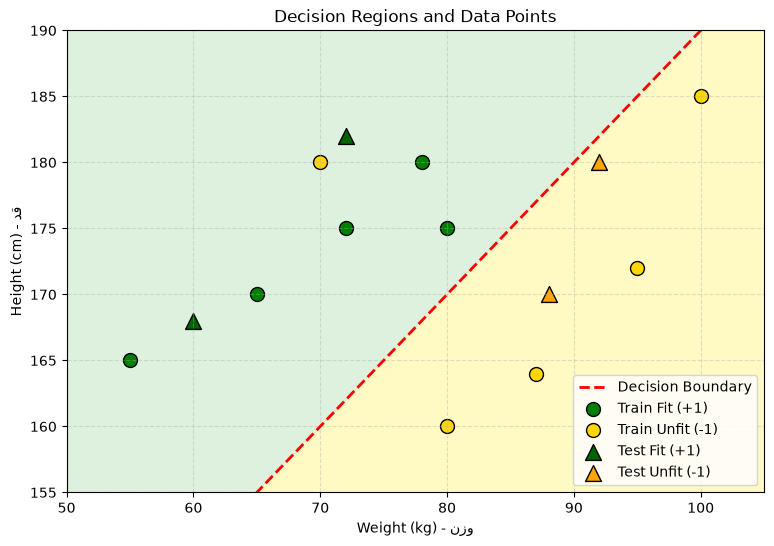

In [7]:
x1_min, x1_max = 50, 105
x2_min, x2_max = 155, 190

xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                       np.linspace(x2_min, x2_max, 300))

grid_points = np.c_[xx1.ravel(), xx2.ravel()]
Z = predict(grid_points, best_w0, best_w1, best_w2)
Z = Z.reshape(xx1.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx1, xx2, Z, levels=[-2, 0, 2], colors=['#FFF59D', '#C8E6C9'], alpha=0.6)

x1_line = np.linspace(x1_min, x1_max, 200)
x2_line = -(best_w0 + best_w1 * x1_line) / best_w2
plt.plot(x1_line, x2_line, 'r--', linewidth=2, label='Decision Boundary')

fit_mask = (y_train == 1)
unfit_mask = (y_train == -1)
plt.scatter(X_train[fit_mask, 0], X_train[fit_mask, 1], color='green', s=100, edgecolors='k', label='Train Fit (+1)')
plt.scatter(X_train[unfit_mask, 0], X_train[unfit_mask, 1], color='gold', s=100, edgecolors='k', label='Train Unfit (-1)')

test_fit = (y_test == 1)
test_unfit = (y_test == -1)
plt.scatter(X_test[test_fit, 0], X_test[test_fit, 1], color='darkgreen', marker='^', s=130, edgecolors='k', label='Test Fit (+1)')
plt.scatter(X_test[test_unfit, 0], X_test[test_unfit, 1], color='orange', marker='^', s=130, edgecolors='k', label='Test Unfit (-1)')

plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.xlabel('Weight (kg) - وزن')
plt.ylabel('Height (cm) - قد')
plt.title('Decision Regions and Data Points')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()